<a href="https://colab.research.google.com/github/Jafar260/ai_prediksi_pengguna_internet/blob/main/notebooks/Prediksi_Pengguna_Internet_Indonesia_Per_Cell_(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prediksi Jumlah Pengguna Internet di Indonesia
## Berdasarkan Perkembangan Infrastruktur Digital

Kode telah dipisahkan menjadi beberapa cell berdasarkan tahapan proyek. Jalankan cell dari atas ke bawah. Pastikan file `Dataset Cleaning.xlsx` tersedia atau unggah ketika diminta.

# 1. Impor Pustaka (Libraries)

In [1]:
import io
import os
import sys
from google.colab import files
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    from tabulate import tabulate
except ImportError:
    os.system("pip install tabulate")
    from tabulate import tabulate

# 2. Memuat Dataset

In [2]:
file_path = "Dataset Cleaning.xlsx"

if not os.path.exists(file_path):
    print('\\nSilakan unggah file "Dataset Cleaning.xlsx":')
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df = pd.read_excel(io.BytesIO(uploaded[file_name]))
else:
    df = pd.read_excel(file_path)

print("\\n==================================")
print("     DATASET BERHASIL DIMUAT      ")
print("==================================")
print(tabulate(df.head(6), headers="keys", tablefmt="grid", showindex=True))

\nSilakan unggah file "Dataset Cleaning.xlsx":


Saving Dataset Cleaning.xlsx to Dataset Cleaning.xlsx
\n==================================
     DATASET BERHASIL DIMUAT      
+----+---------+----------------------------+-----------------+--------------+------------------+------------------+
|    |   Tahun |   Pengguna Internet (Juta) |   Penetrasi (%) |   Jumlah BTS |   Cakupan 4G (%) |   Port FO (juta) |
+====+=========+============================+=================+==============+==================+==================+
|  0 |    2020 |                      196.7 |            71.6 |         4500 |             92   |              8.5 |
+----+---------+----------------------------+-----------------+--------------+------------------+------------------+
|  1 |    2021 |                      202.6 |            73.7 |         5200 |             93.5 |              9.2 |
+----+---------+----------------------------+-----------------+--------------+------------------+------------------+
|  2 |    2022 |                      210   |          

# 3. Analisis Korelasi

\n====================================
    SKOR KORELASI TERHADAP TARGET   
+--------------------------+------------------+
| Variabel                 |   Nilai Korelasi |
+==========================+==================+
| Pengguna Internet (Juta) |         1        |
+--------------------------+------------------+
| Tahun                    |         0.998871 |
+--------------------------+------------------+
| Port FO (juta)           |         0.995551 |
+--------------------------+------------------+
| Penetrasi (%)            |         0.992033 |
+--------------------------+------------------+
| Jumlah BTS               |         0.976347 |
+--------------------------+------------------+
| Cakupan 4G (%)           |         0.97442  |
+--------------------------+------------------+


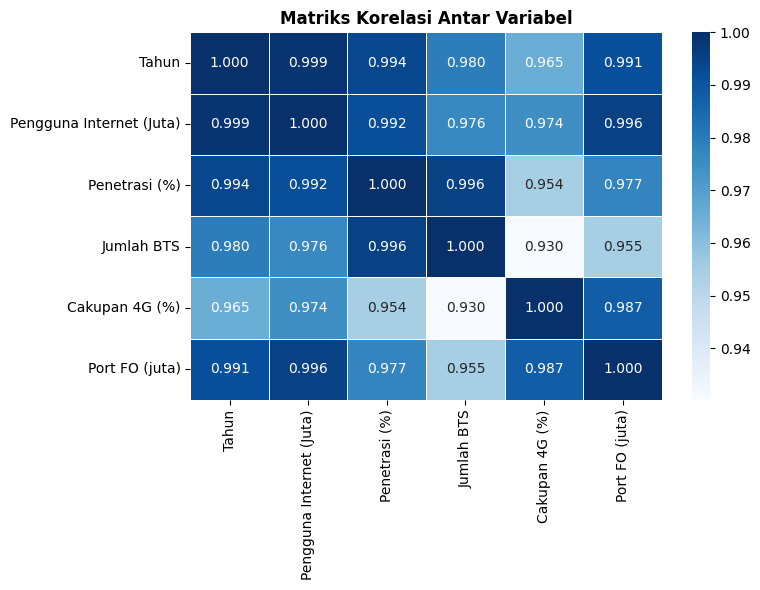

In [3]:
target_column = "Pengguna Internet (Juta)"
corr_matrix = df.corr(numeric_only=True)

print("\\n====================================")
print("    SKOR KORELASI TERHADAP TARGET   ")
print("====================================")
if target_column in corr_matrix.columns:
    corr_target = corr_matrix[[target_column]].sort_values(
        by=target_column, ascending=False
    )
    print(tabulate(corr_target, headers=["Variabel", "Nilai Korelasi"], tablefmt="grid"))
else:
    print(f"Peringatan: Kolom '{target_column}' tidak ditemukan atau bukan numerik.")

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="Blues", fmt=".3f", linewidths=0.5)
plt.title("Matriks Korelasi Antar Variabel", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# 4. Feature Selection (Seleksi Fitur)

In [4]:
selected_features = ["Tahun", "Jumlah BTS", "Port FO (juta)"]

X = df[selected_features]
y = df[target_column]

print("\\n==============================")
print("      FEATURE SELECTION       ")
print("==============================")
print(f"Fitur Terpilih (X) : {list(X.columns)}")
print(f"Target (y)         : {y.name}")

print("\\n=== Tampilan Data X (Fitur) ===")
print(tabulate(X, headers="keys", tablefmt="grid", showindex=True))

print("\\n=== Tampilan Data y (Target) ===")
df_y = pd.DataFrame(y)
print(tabulate(df_y, headers="keys", tablefmt="grid", showindex=True))

\n==============================
      FEATURE SELECTION       
Fitur Terpilih (X) : ['Tahun', 'Jumlah BTS', 'Port FO (juta)']
Target (y)         : Pengguna Internet (Juta)
\n=== Tampilan Data X (Fitur) ===
+----+---------+--------------+------------------+
|    |   Tahun |   Jumlah BTS |   Port FO (juta) |
+====+=========+==============+==================+
|  0 |    2020 |         4500 |              8.5 |
+----+---------+--------------+------------------+
|  1 |    2021 |         5200 |              9.2 |
+----+---------+--------------+------------------+
|  2 |    2022 |         5800 |             10.1 |
+----+---------+--------------+------------------+
|  3 |    2023 |         6200 |             10.7 |
+----+---------+--------------+------------------+
|  4 |    2024 |         6500 |             11.5 |
+----+---------+--------------+------------------+
|  5 |    2025 |         6747 |             12.9 |
+----+---------+--------------+------------------+
\n=== Tampilan Data y (Targe

# 5. Ekspor Dataset Hasil Seleksi Fitur

In [5]:
df_selected = X.copy()
df_selected[target_column] = y

df_selected.to_csv("dataset_selected_features.csv", index=False)
df_selected.to_excel("dataset_selected_features.xlsx", index=False)

print("\\n=== Ekspor Dataset Hasil Seleksi Fitur ===")
print("File tersimpan di direktori kerja: 'dataset_selected_features.csv' dan 'dataset_selected_features.xlsx'")

\n=== Ekspor Dataset Hasil Seleksi Fitur ===
File tersimpan di direktori kerja: 'dataset_selected_features.csv' dan 'dataset_selected_features.xlsx'


# 6. Train-Test Split

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\\n==============================")
print("      TRAIN - TEST SPLIT      ")
print("==============================")
print(f"Total Sampel Dataset     : {len(df)} baris")
print(f"Jumlah Data Latih (80%)  : {len(X_train)} baris")
print(f"Jumlah Data Uji (20%)    : {len(X_test)} baris")

print("\\n=== Data Latih Fitur (X_train) ===")
print(tabulate(X_train, headers="keys", tablefmt="grid", showindex=True))

print("\\n=== Data Uji Fitur (X_test) ===")
print(tabulate(X_test, headers="keys", tablefmt="grid", showindex=True))

print("\\n=== Data Latih Target (y_train) ===")
print(tabulate(pd.DataFrame(y_train), headers="keys", tablefmt="grid", showindex=True))

print("\\n=== Data Uji Target (y_test) ===")
print(tabulate(pd.DataFrame(y_test), headers="keys", tablefmt="grid", showindex=True))

\n==============================
      TRAIN - TEST SPLIT      
Total Sampel Dataset     : 6 baris
Jumlah Data Latih (80%)  : 4 baris
Jumlah Data Uji (20%)    : 2 baris
\n=== Data Latih Fitur (X_train) ===
+----+---------+--------------+------------------+
|    |   Tahun |   Jumlah BTS |   Port FO (juta) |
+====+=========+==============+==================+
|  5 |    2025 |         6747 |             12.9 |
+----+---------+--------------+------------------+
|  2 |    2022 |         5800 |             10.1 |
+----+---------+--------------+------------------+
|  4 |    2024 |         6500 |             11.5 |
+----+---------+--------------+------------------+
|  3 |    2023 |         6200 |             10.7 |
+----+---------+--------------+------------------+
\n=== Data Uji Fitur (X_test) ===
+----+---------+--------------+------------------+
|    |   Tahun |   Jumlah BTS |   Port FO (juta) |
+====+=========+==============+==================+
|  0 |    2020 |         4500 |              8

# 7. Pemodelan Machine Learning

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

# Algoritma 1: Linear Regression
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Algoritma 2: Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

print("\\n========================================")
print("        PEMODELAN BERHASIL DILATIH      ")
print("========================================")
print("1. Model Linear Regression : Berhasil dilatih")
print("2. Model Random Forest     : Berhasil dilatih")

\n========================================
        PEMODELAN BERHASIL DILATIH      
1. Model Linear Regression : Berhasil dilatih
2. Model Random Forest     : Berhasil dilatih


# 8. Evaluasi Model

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_lr = model_lr.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

df_evaluasi = pd.DataFrame({
    "Algoritma": ["Linear Regression", "Random Forest Regressor"],
    "R2 Score": [f"{r2_lr:.4f}", f"{r2_rf:.4f}"],
    "MAE": [f"{mae_lr:.4f}", f"{mae_rf:.4f}"],
    "RMSE": [f"{rmse_lr:.4f}", f"{rmse_rf:.4f}"],
})

print("\\n==============================")
print("        EVALUASI MODEL        ")
print("==============================")
print(tabulate(df_evaluasi, headers="keys", tablefmt="grid", showindex=False))

\n==============================
        EVALUASI MODEL        
+-------------------------+------------+---------+---------+
| Algoritma               |   R2 Score |     MAE |    RMSE |
+=========================+============+=========+=========+
| Linear Regression       |     0.8472 |  0.9131 |  1.1532 |
+-------------------------+------------+---------+---------+
| Random Forest Regressor |   -18.9299 | 12.835  | 13.1697 |
+-------------------------+------------+---------+---------+


# 9. Prediksi dan Interpretasi Tahun 2026

In [9]:
data_2026 = np.array([[2026, 7000, 14.0]])
pred_2026 = model_lr.predict(data_2026)[0]

df_koef = pd.DataFrame({
    "Fitur": selected_features,
    "Koefisien (Pengaruh)": model_lr.coef_,
})

print("\\n======================================")
print("       PREDIKSI & INTERPRETASI        ")
print("======================================")
print(f"Estimasi Pengguna Internet Indonesia Tahun 2026: {pred_2026:.2f} Juta Pengguna")

print("\\n=== Pengaruh Masing-Masing Fitur Terhadap Prediksi ===")
print(tabulate(df_koef, headers="keys", tablefmt="grid", showindex=False))

\n======================================
       PREDIKSI & INTERPRETASI        
Estimasi Pengguna Internet Indonesia Tahun 2026: 236.21 Juta Pengguna
\n=== Pengaruh Masing-Masing Fitur Terhadap Prediksi ===
+----------------+------------------------+
| Fitur          |   Koefisien (Pengaruh) |
+================+========================+
| Tahun          |             1.58259    |
+----------------+------------------------+
| Jumlah BTS     |             0.00445344 |
+----------------+------------------------+
| Port FO (juta) |             3.72672    |
+----------------+------------------------+


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# 10. Kesimpulan

In [10]:
print("\\n=========================")
print("        KESIMPULAN       ")
print("=========================")
print(
    f"1. Linear Regression: R² = {r2_lr:.4f}, MAE = {mae_lr:.4f}, RMSE = {rmse_lr:.4f}."
)
print(
    f"2. Random Forest Regressor: R² = {r2_rf:.4f}, MAE = {mae_rf:.4f}, RMSE = {rmse_rf:.4f}."
)
print(
    f"3. Prediksi jumlah pengguna internet Indonesia tahun 2026 dengan Linear Regression: "
    f"{pred_2026:.2f} juta pengguna."
)
print(
    "Catatan: Pilih model terbaik berdasarkan hasil metrik evaluasi aktual. "
    "Hasil prediksi merupakan estimasi dan bergantung pada kualitas serta cakupan dataset."
)

\n=========================
        KESIMPULAN       
1. Linear Regression: R² = 0.8472, MAE = 0.9131, RMSE = 1.1532.
2. Random Forest Regressor: R² = -18.9299, MAE = 12.8350, RMSE = 13.1697.
3. Prediksi jumlah pengguna internet Indonesia tahun 2026 dengan Linear Regression: 236.21 juta pengguna.
Catatan: Pilih model terbaik berdasarkan hasil metrik evaluasi aktual. Hasil prediksi merupakan estimasi dan bergantung pada kualitas serta cakupan dataset.
